In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

Loading DataSet

In [ ]:
df = pd.read_csv('weatherAUS.csv')

In [ ]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

Data Visulation and Cleaning

/tmp/ipykernel_19852/3433640025.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = df['RainTomorrow'], palette= cols)


<Axes: xlabel='RainTomorrow', ylabel='count'>

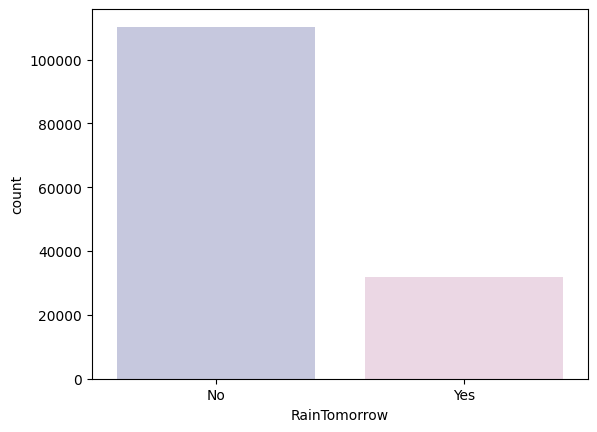

In [ ]:
cols = ['#C2C4E2', '#EED4E5']
sns.countplot(x = df['RainTomorrow'], palette= cols)

<Axes: >

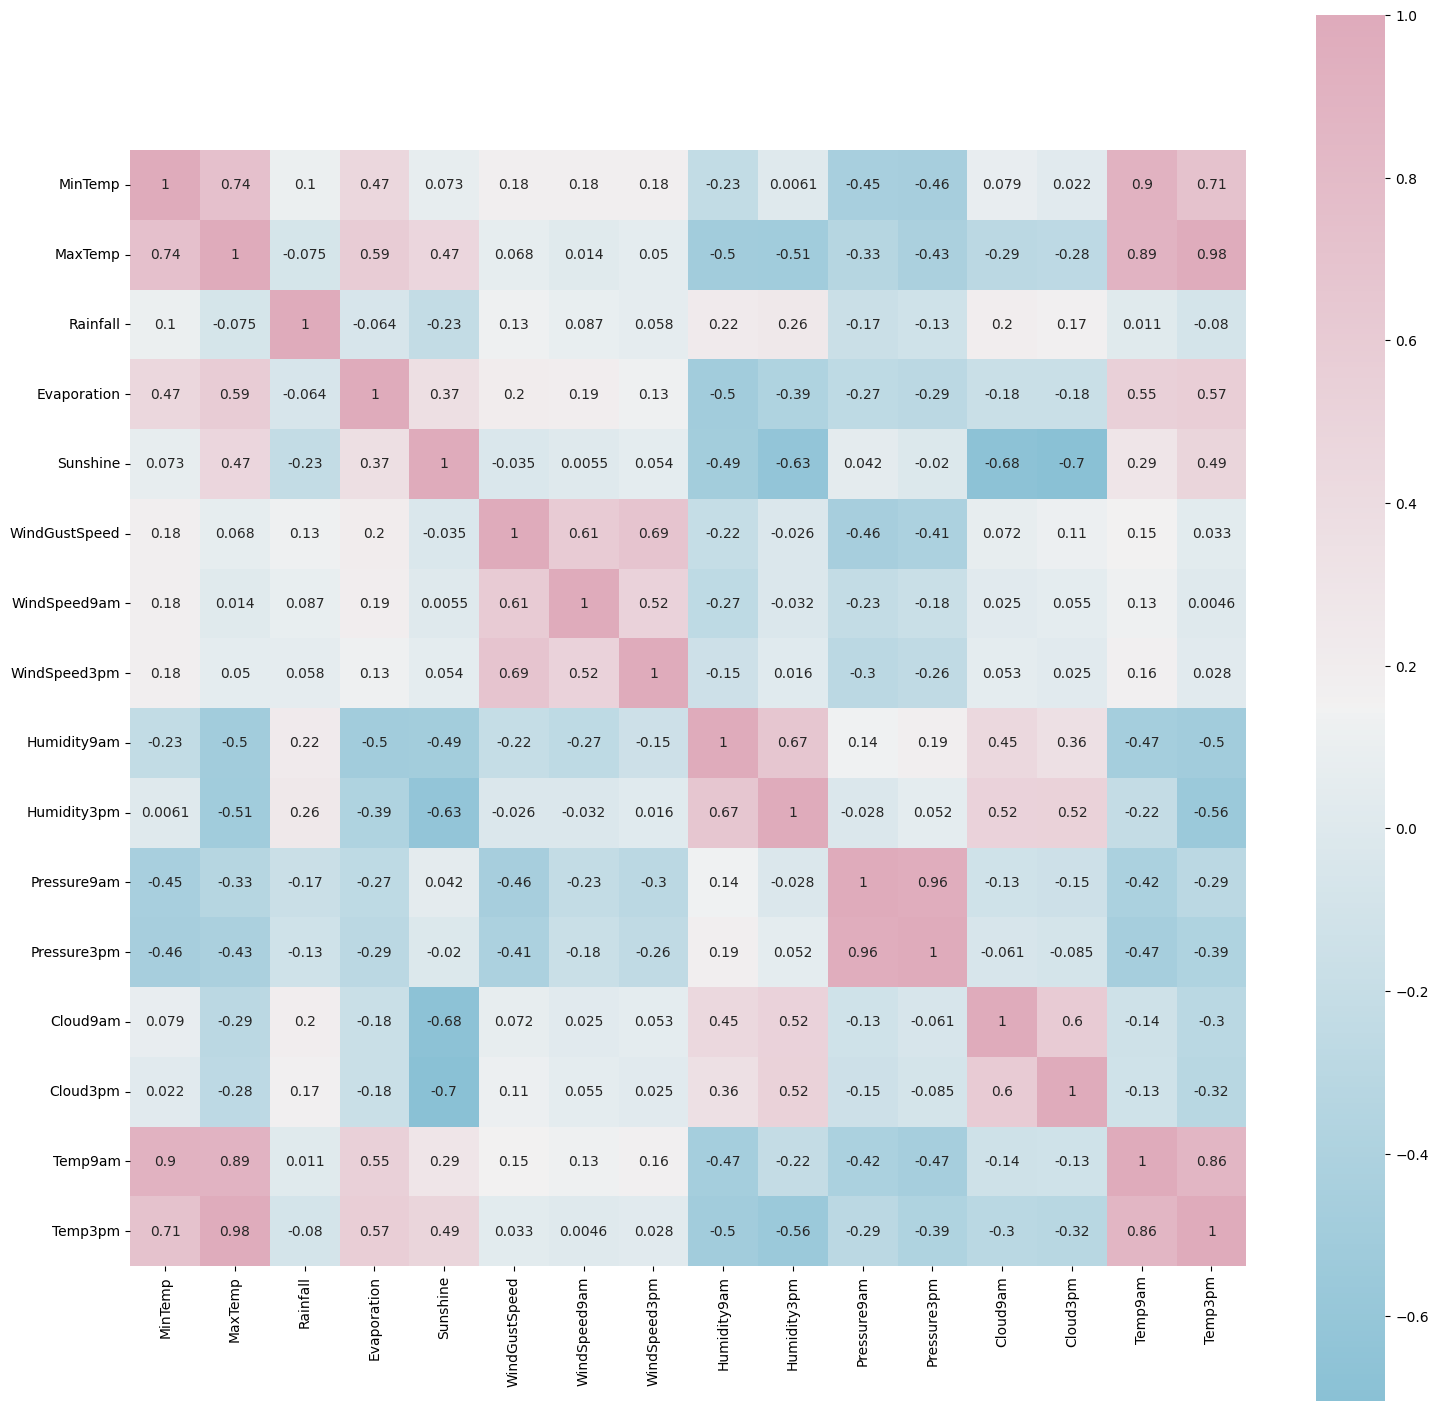

In [ ]:
# Correlation amongst numeric attribute

corrmat = df.corr(numeric_only=True)
cmap = sns.diverging_palette(220, -10, s = 50, l = 75, n = 6, as_cmap=True)
plt.subplots(figsize = (18, 18))
sns.heatmap(corrmat,cmap= cmap, annot = True, square = True)

In [ ]:
#Parsing datetime
#exploring the length of date objects
lengths = df['Date'].str.len()
lengths.value_counts()

,count
Date,
10,145460


In [ ]:
# There don't seem to be any error in dates so parsing values into datetime
df['Date'] = pd.to_datetime(df['Date'])

# creating a column of year
df['Year'] = df.Date.dt.year

# function to encode datetime into cyclic parameters.
#As I am planning to use this data in a neural network I prefer the months and days in a cyclic continuous feature.

def encode(df, col, max_val):
  df[col + '_sin'] = np.sin(2 * np.pi * df[col]/max_val)
  df[col + '_cos'] = np.cos(2 * np.pi * df[col]/max_val)
  return df

df['month'] = df.Date.dt.month
df = encode(df, 'month', 12)

df['day'] = df.Date.dt.day
df = encode(df, 'day', 31)

df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Temp3pm,RainToday,RainTomorrow,Year,month,month_sin,month_cos,day,day_sin,day_cos
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,21.8,No,No,2008,12,-2.449294e-16,1.0,1,0.201299,0.979530
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,24.3,No,No,2008,12,-2.449294e-16,1.0,2,0.394356,0.918958
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,23.2,No,No,2008,12,-2.449294e-16,1.0,3,0.571268,0.820763
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,26.5,No,No,2008,12,-2.449294e-16,1.0,4,0.724793,0.688967
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,29.7,No,No,2008,12,-2.449294e-16,1.0,5,0.848644,0.528964


Text(0, 0.5, 'Days in months')

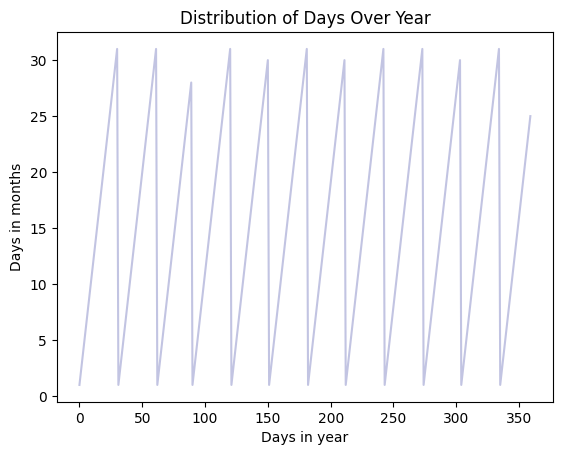

In [ ]:
# roughly a year's a span section
section = df[:360]
tm = section['day'].plot(color = '#C2C4E2')
tm.set_title('Distribution of Days Over Year')
tm.set_xlabel('Days in year')
tm.set_ylabel('Days in months')

Text(0, 0.5, 'Cosine Encoded Months')

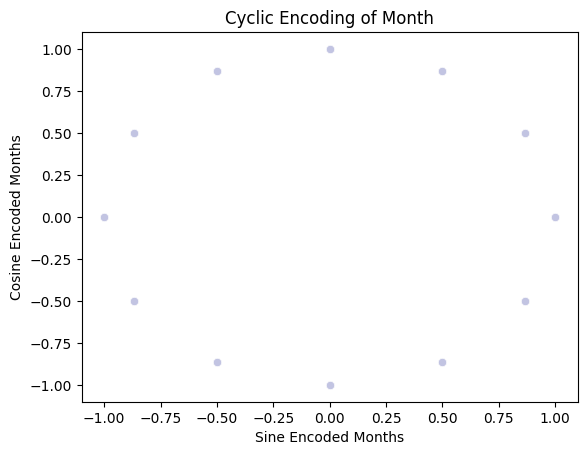

In [ ]:
cyclic_month = sns.scatterplot(x = 'month_sin', y = 'month_cos', data = df, color = '#C2C4E2')
cyclic_month.set_title('Cyclic Encoding of Month')
cyclic_month.set_xlabel('Sine Encoded Months')
cyclic_month.set_ylabel('Cosine Encoded Months')

Text(0, 0.5, 'Cosine Enocoded Days')

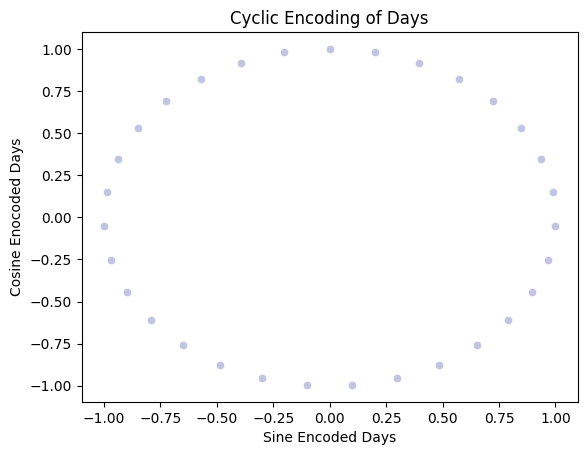

In [ ]:
cyclic_day = sns.scatterplot(x= 'day_sin', y = 'day_cos', data = df, color = '#C2C4E2')
cyclic_day.set_title('Cyclic Encoding of Days')
cyclic_day.set_xlabel('Sine Encoded Days')
cyclic_day.set_ylabel('Cosine Enocoded Days')

In [ ]:
# get list of categorical Variables
s = (df.dtypes == 'object')
object_cols = list(s[s].index)

print('Categorical variables: ')
print(object_cols)

Categorical variables: 
['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']


In [ ]:
# Missing values in categorical variables
for i in object_cols:
  print(i, df[i].isnull().sum())

Location 0
WindGustDir 10326
WindDir9am 10566
WindDir3pm 4228
RainToday 3261
RainTomorrow 3267


In [ ]:
# Filling the missing values with mode of the column in value
for i in object_cols:
  df[i].fillna(df[i].mode()[0], inplace = True)

/tmp/ipykernel_19852/3979473873.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].mode()[0], inplace = True)


In [ ]:
t = (df.dtypes == 'float64')
num_cols = list(t[t].index)

print('Numeric variables:')
print(num_cols)

Numeric variables:
['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'month_sin', 'month_cos', 'day_sin', 'day_cos']


In [ ]:
# filling missing values with median of the column in value

for i in num_cols:
  df[i].fillna(df[i].median(), inplace = True)

df.info()

/tmp/ipykernel_19852/2432423270.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].median(), inplace = True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 30 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[ns]
 1   Location       145460 non-null  object        
 2   MinTemp        145460 non-null  float64       
 3   MaxTemp        145460 non-null  float64       
 4   Rainfall       145460 non-null  float64       
 5   Evaporation    145460 non-null  float64       
 6   Sunshine       145460 non-null  float64       
 7   WindGustDir    145460 non-null  object        
 8   WindGustSpeed  145460 non-null  float64       
 9   WindDir9am     145460 non-null  object        
 10  WindDir3pm     145460 non-null  object        
 11  WindSpeed9am   145460 non-null  float64       
 12  WindSpeed3pm   145460 non-null  float64       
 13  Humidity9am    145460 non-null  float64       
 14  Humidity3pm    145460 non-null  float64       
 15  

Text(0, 0.5, 'Rainfall')

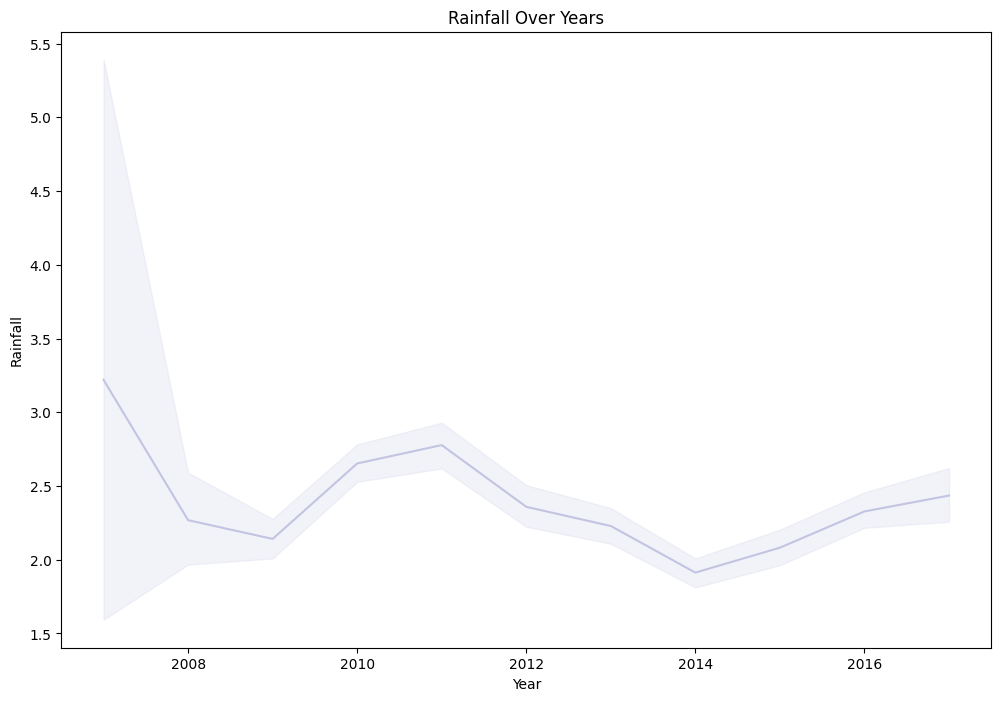

In [ ]:
plt.figure(figsize=(12, 8))
sns.lineplot(x= 'Year', y = 'Rainfall', data = df, color = '#C2C4E2')
plt.title('Rainfall Over Years')
plt.xlabel('Year')
plt.ylabel('Rainfall')

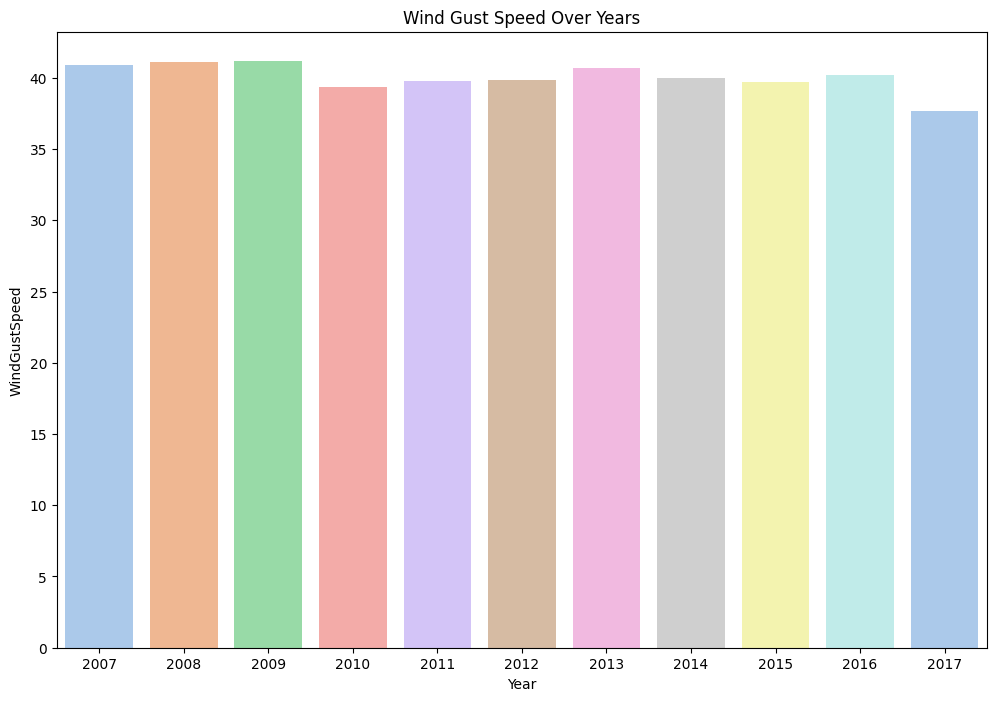

In [ ]:
plt.figure(figsize = (12, 8))
sns.barplot(x = 'Year', y = 'WindGustSpeed', data = df, palette='pastel', hue = 'Year', legend = False, errorbar=None)
plt.title('Wind Gust Speed Over Years')
plt.xlabel('Year')
plt.ylabel('WindGustSpeed')
plt.show()

# **Data Preprocessing**

In [ ]:
# Apply label encoder to each column with categorical data
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
for i in object_cols:
  df[i] = label_encoder.fit_transform(df[i])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 30 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[ns]
 1   Location       145460 non-null  int64         
 2   MinTemp        145460 non-null  float64       
 3   MaxTemp        145460 non-null  float64       
 4   Rainfall       145460 non-null  float64       
 5   Evaporation    145460 non-null  float64       
 6   Sunshine       145460 non-null  float64       
 7   WindGustDir    145460 non-null  int64         
 8   WindGustSpeed  145460 non-null  float64       
 9   WindDir9am     145460 non-null  int64         
 10  WindDir3pm     145460 non-null  int64         
 11  WindSpeed9am   145460 non-null  float64       
 12  WindSpeed3pm   145460 non-null  float64       
 13  Humidity9am    145460 non-null  float64       
 14  Humidity3pm    145460 non-null  float64       
 15  

In [120]:
# prepairing attributes of scale data
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

features = df.drop(['RainTomorrow', 'Date', 'day', 'month'], axis = 1)
target = df['RainTomorrow']

# set up standard scaler for the features
col_names = list(features.columns)
s_scaler = preprocessing.StandardScaler()
features = s_scaler.fit_transform(features)
features = pd.DataFrame(features, columns = col_names)

features.describe().T

,count,mean,std,min,25%,50%,75%,max
Location,145460.0,7.815677e-18,1.000003,-1.672228,-0.899139,0.014511,0.857881,1.701250
MinTemp,145460.0,-4.501830e-16,1.000003,-3.250525,-0.705659,-0.030170,0.723865,3.410112
MaxTemp,145460.0,3.001220e-16,1.000003,-3.952405,-0.735852,-0.086898,0.703133,3.510563
Rainfall,145460.0,7.815677e-18,1.000003,-0.275097,-0.275097,-0.275097,-0.203581,43.945571
Evaporation,145460.0,-3.282584e-17,1.000003,-1.629472,-0.371139,-0.119472,0.006361,43.985108
Sunshine,145460.0,-5.424080e-16,1.000003,-2.897217,0.076188,0.148710,0.257494,2.360634
WindGustDir,145460.0,6.252542e-18,1.000003,-1.724209,-0.872075,0.193094,1.045228,1.471296
WindGustSpeed,145460.0,1.824961e-16,1.000003,-2.588407,-0.683048,-0.073333,0.460168,7.243246
WindDir9am,145460.0,7.190423e-17,1.000003,-1.550000,-0.885669,0.000105,0.885879,1.771653
WindDir3pm,145460.0,8.284618e-17,1.000003,-1.718521,-0.837098,0.044324,0.925747,1.586813


/tmp/ipykernel_19852/4126102138.py:5: UserWarning: 
The palette list has fewer values (5) than needed (26) and will cycle, which may produce an uninterpretable plot.
  sns.boxenplot(data = features, palette=colors)


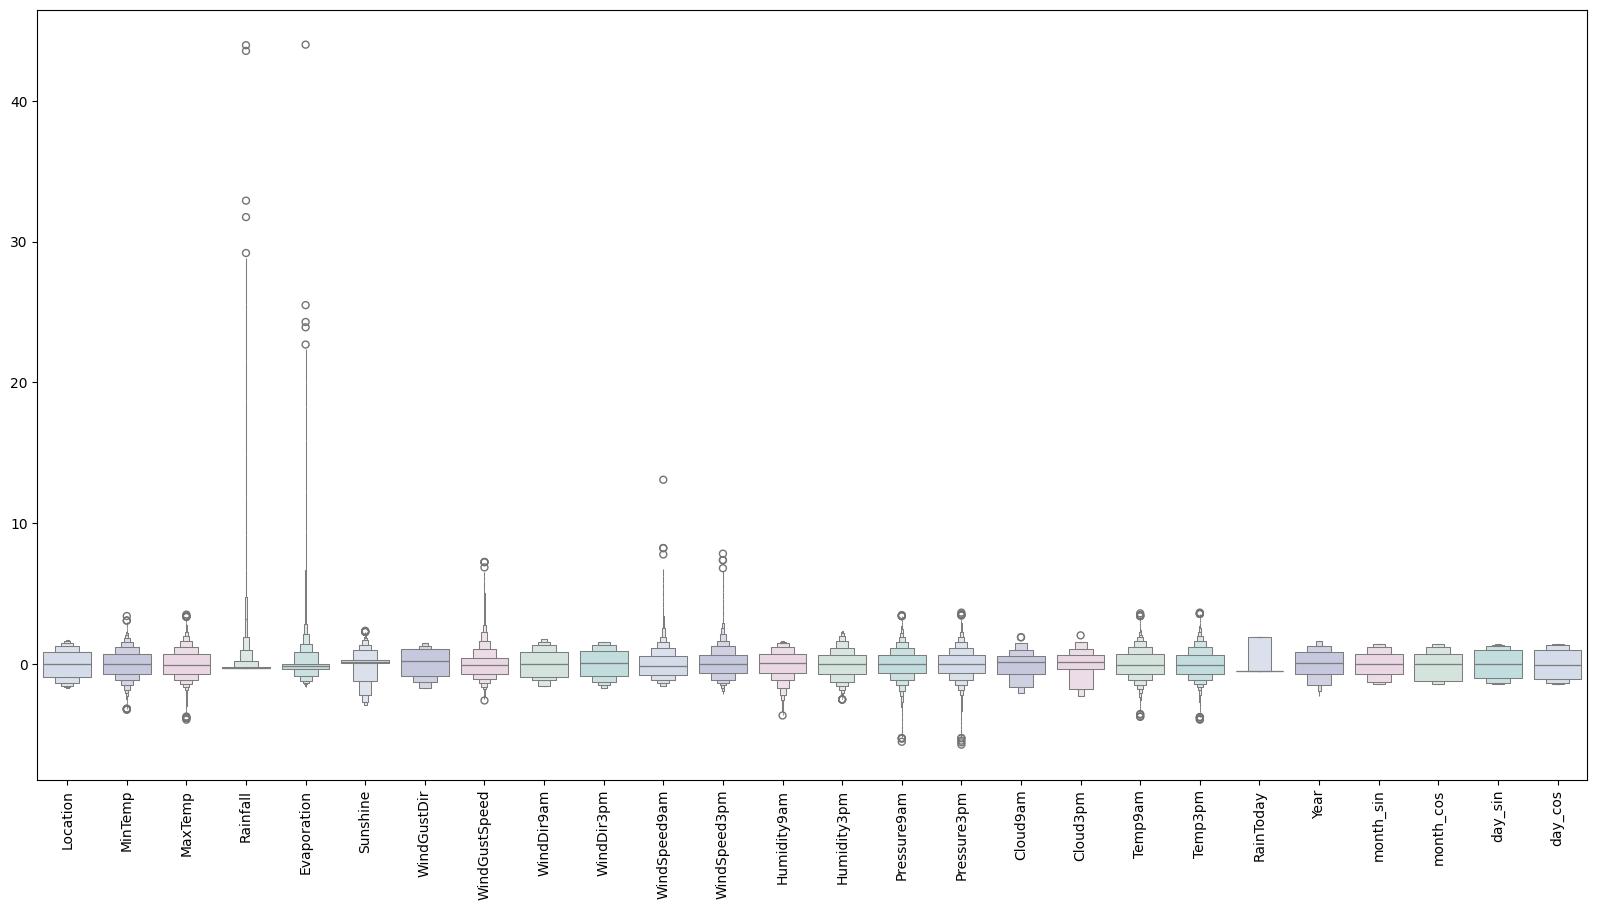

In [ ]:
# Detecting outliers
# looking at the scaled features
colors = ["#D0DBEE", "#C2C4E2", "#EED4E5", "#D1E6DC", "#BDE2E2"]
plt.figure(figsize=(20, 10))
sns.boxenplot(data = features, palette=colors)
plt.xticks(rotation  = 90)
plt.show()

In [ ]:
# full data for
features['RainTomorrow'] = target

# Dropping with outlier
features = features[(features['MinTemp']<2.3)&(features['MinTemp']>-2.3)]
features = features[(features['MaxTemp']<2.3)&(features['MaxTemp']>-2.3)]
features = features[(features['Rainfall']<4.5)]
features = features[(features['Evaporation']<2.8)]
features = features[(features['Sunshine']<2.1)]
features = features[(features['WindGustSpeed']<4)&(features['WindGustSpeed']>-4)]
features = features[(features['WindSpeed9am']<4)]
features = features[(features['WindSpeed3pm']<2.5)]
features = features[(features['Humidity9am']>-3)]
features = features[(features['Humidity3pm']>-2.2)]
features = features[(features['Pressure9am']<2)&(features['Pressure9am']>-2.7)]
features = features[(features['Pressure3pm']<2)&(features['Pressure3pm']>-2.7)]
features = features[(features['Cloud9am']<1.8)]
features = features[(features['Cloud3pm']<2)]
features = features[(features['Temp9am']<2.3)&(features['Temp9am']>-2)]
features = features[(features['Temp3pm']<2.3)&(features['Temp3pm']>-2)]

features.shape

(127595, 27)

/tmp/ipykernel_19852/2050916853.py:2: UserWarning: 
The palette list has fewer values (5) than needed (27) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(data = features, palette=colors)


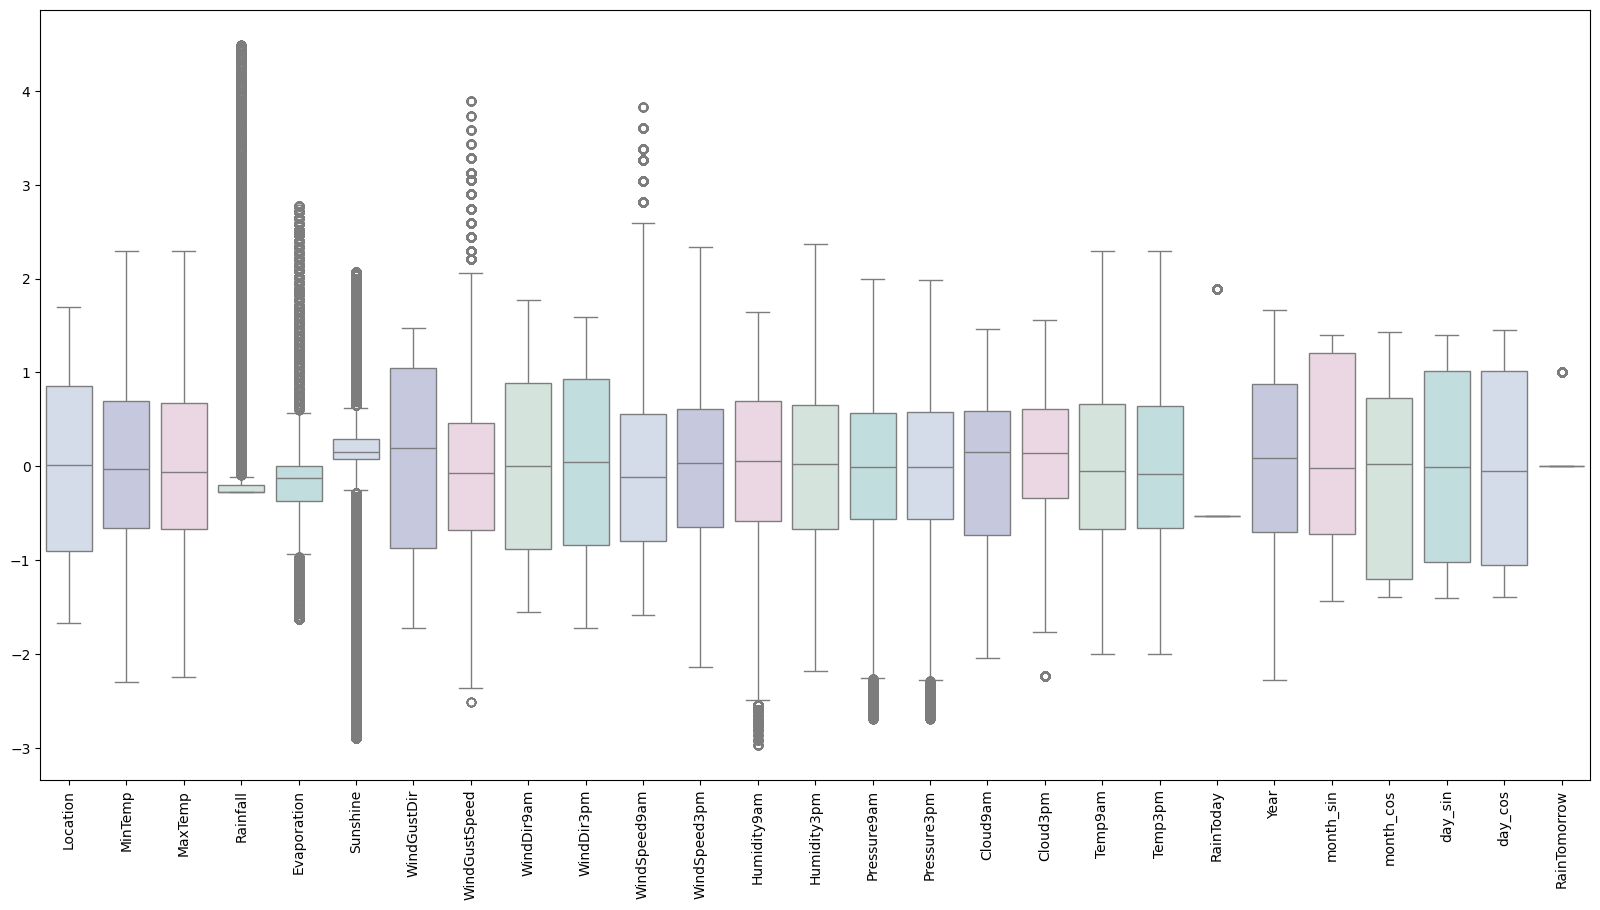

In [ ]:
plt.figure(figsize=(20, 10))
sns.boxplot(data = features, palette=colors)
plt.xticks(rotation = 90)
plt.show()

In [ ]:
print(features.columns.tolist())


['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'Year', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'RainTomorrow']


Model **Building**

In [ ]:
X = features.drop(['RainTomorrow'], axis = 1)
y = features['RainTomorrow']

In [ ]:
# Splitting test and training sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

X.shape

(127595, 26)

In [ ]:
import tensorflow
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization, Dropout, LSTM
from keras.utils import to_categorical
from keras.optimizers import Adam
from keras import regularizers
from keras import callbacks
from keras.callbacks import EarlyStopping

In [ ]:
# Early stopping
early_stopping = callbacks.EarlyStopping(
    min_delta = 0.001,
    patience = 20,
    restore_best_weights = True
)

# Initialising the NN
model = Sequential()

# layers

model.add(Dense(32, activation='relu', kernel_initializer='uniform', input_dim = 26))
model.add(Dense(32, activation= 'relu', kernel_initializer= 'uniform'))
model.add(Dense(16, activation = 'relu', kernel_initializer='uniform'))
model.add(Dropout(0.25))
model.add(Dense(8, activation = 'relu', kernel_initializer='uniform'))
model.add(Dropout(0.5))
model.add(Dense(1, activation = 'sigmoid'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593 (10.13 KB)

 Trainable params: 2,593 (10.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compiling the ANN
opt = Adam(learning_rate = 0.00009)
model.compile(optimizer = opt, loss = 'binary_crossentropy', metrics = ['accuracy'])

In [ ]:
history = model.fit(X_train, y_train, batch_size = 32, epochs = 150, callbacks = [early_stopping], validation_split = 0.2)

Epoch 1/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.7860 - loss: 0.4626 - val_accuracy: 0.7862 - val_loss: 0.3854
Epoch 2/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8091 - loss: 0.4107 - val_accuracy: 0.8413 - val_loss: 0.3778
Epoch 3/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8137 - loss: 0.4050 - val_accuracy: 0.8446 - val_loss: 0.3730
Epoch 4/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8139 - loss: 0.4013 - val_accuracy: 0.8458 - val_loss: 0.3685
Epoch 5/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8159 - loss: 0.3970 - val_accuracy: 0.8470 - val_loss: 0.3656
Epoch 6/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8162 - loss: 0.3938 - val_accuracy: 0.8468 - val_loss: 0.3634
Epoch 7/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8152 - loss: 0.3956 - val_accuracy: 0.8480 - val_loss: 0.3624
Epoch 8/150
2552/2552 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8162 - loss: 

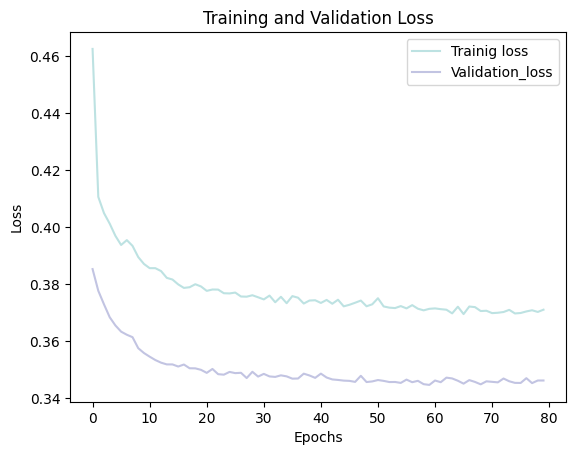

In [ ]:
history_df = pd.DataFrame(history.history)
plt.plot(history_df.loc[:, ['loss']], '#BDE2E2', label = 'Trainig loss')
plt.plot(history_df.loc[:, ['val_loss']], '#C2C4E2', label = 'Validation_loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc= 'best')
plt.show()

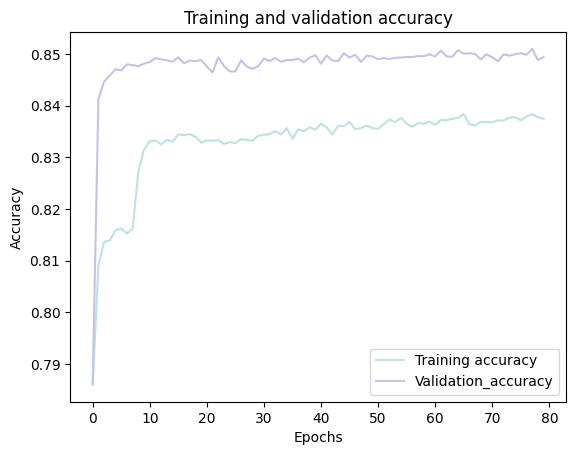

In [ ]:
history_df = pd.DataFrame(history.history)
plt.plot(history_df.loc[:, ['accuracy']], '#BDE2E2', label = 'Training accuracy')
plt.plot(history_df.loc[:, ['val_accuracy']], '#C2C4E4', label = 'Validation_accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Predicting the test results
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5)

798/798 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

<Axes: >

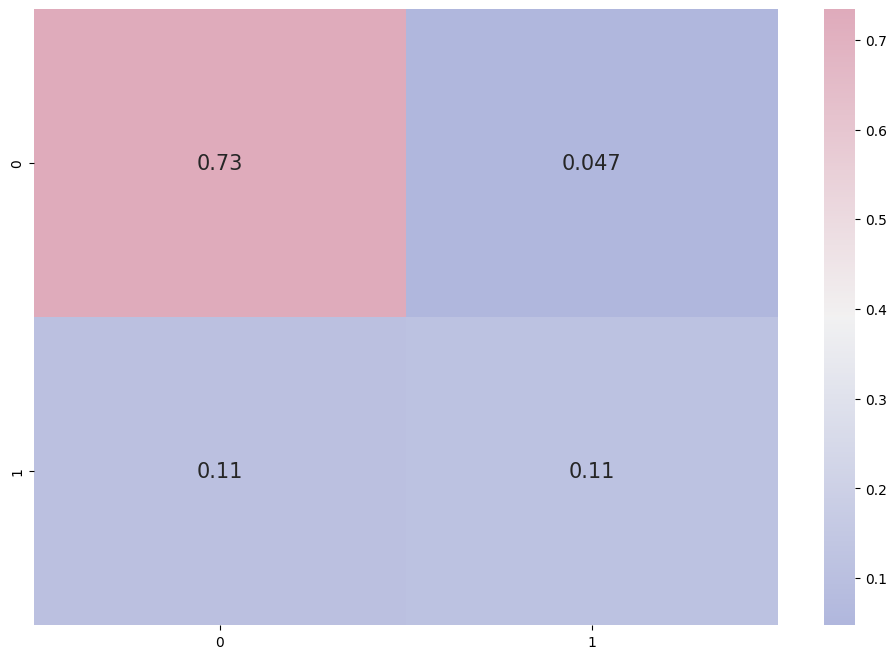

In [ ]:
cmap1 = sns.diverging_palette(260, -10, s= 50, l = 75, n = 5, as_cmap = True)
plt.subplots(figsize = (12, 8))
cf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(cf_matrix/np.sum(cf_matrix), cmap = cmap1, annot = True, annot_kws = {'size':15})

In [ ]:
print('Accuracy', accuracy_score(y_test, y_pred))
print('classification Report', classification_report(y_test, y_pred))

Accuracy 0.8469375759238215
classification Report               precision    recall  f1-score   support

           0       0.87      0.94      0.91     19942
           1       0.70      0.52      0.60      5577

    accuracy                           0.85     25519
   macro avg       0.79      0.73      0.75     25519
weighted avg       0.84      0.85      0.84     25519

